Karol Alexis Alvarado Davila - A01751711

Inteligencia artificial avanzada para la ciencia de datos

TC3009C.601

Momento de Retroalimentacion: Modulo 5 Implementacion de un modelo de deep learning. (Portafolio Implementacion)

viernes 13 de noviembre de 2026

Introduccion

En la sangre hay varios tipos de globulos blancos y cada uno cumple una funcion distinta en el sistema inmune. El conteo diferencial, que es saber cuantos hay de cada tipo en una muestra, forma parte de la biometria hematica y ayuda a orientar el diagnostico de infecciones, alergias y enfermedades de la sangre. Cuando este conteo se hace a mano, una persona revisa el frotis en el microscopio y clasifica celula por celula, lo cual es lento y depende de su experiencia.

El problema que se busca resolver es clasificar de forma automatica la imagen de un globulo blanco en uno de cuatro tipos: eosinofilo, linfocito, monocito o neutrofilo. Es un problema de clasificacion de imagenes con 4 clases, y se resuelve con una red neuronal convolucional, porque lo que distingue a cada tipo es la forma del nucleo y la textura de la celula, que son patrones espaciales.

Datos

Paso 1. Fuente y carga de los datos

Se usa el dataset Blood Cell Images, publicado por Paul Mooney en Kaggle: https://www.kaggle.com/datasets/paultimothymooney/blood-cells

El dataset no se incluye en el repositorio por su peso. Para correr el notebook se descarga el zip de la liga anterior y la carpeta dataset2-master se coloca dentro de la carpeta data, en la raiz del repositorio. Las imagenes ya vienen separadas en carpetas por conjunto (TRAIN, TEST y TEST_SIMPLE) y por clase.

In [1]:
%matplotlib inline
import os
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(0)
tf.random.set_seed(0)
plt.rcParams["figure.figsize"] = (8, 4)

In [2]:
# ruta de las imagenes y nombres de las clases
ruta = pathlib.Path("..") / "data" / "dataset2-master" / "images"
conjuntos = ["TRAIN", "TEST", "TEST_SIMPLE"]
clases = sorted(os.listdir(ruta / "TRAIN"))
print("Clases:", clases)

Clases: ['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL']


Paso 2. Imagenes por clase y por conjunto

            TRAIN  TEST  TEST_SIMPLE
EOSINOPHIL   2497   623           13
LYMPHOCYTE   2483   620            6
MONOCYTE     2478   620            4
NEUTROPHIL   2499   624           48
Total        9957  2487           71


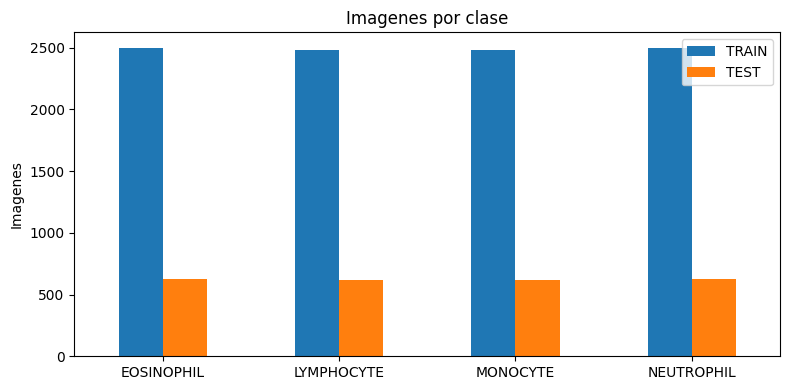

In [3]:
# conteo de imagenes por clase en cada conjunto
conteo = pd.DataFrame(index=clases)
for conjunto in conjuntos:
    conteo[conjunto] = [len(os.listdir(ruta / conjunto / clase)) for clase in clases]
conteo.loc["Total"] = conteo.sum()
print(conteo)

# grafica de barras de TRAIN y TEST
conteo.drop("Total")[["TRAIN", "TEST"]].plot.bar(rot=0)
plt.ylabel("Imagenes")
plt.title("Imagenes por clase")
plt.tight_layout()
plt.show()

Hay 9957 imagenes en TRAIN y 2487 en TEST. En ambos conjuntos las cuatro clases tienen casi la misma cantidad, alrededor de 2490 imagenes por clase en TRAIN y 620 en TEST, por lo que el dataset esta balanceado y el accuracy es una metrica adecuada. Como hay 4 clases balanceadas, un modelo que adivina al azar tendria un accuracy cercano a 25 por ciento, y ese es el punto de comparacion.

TEST_SIMPLE es distinto: tiene solo 71 imagenes y esta desbalanceado, con 48 neutrofilos y 4 monocitos.

Paso 3. Tamano y formato de las imagenes

In [4]:
# tamano de una muestra de 200 imagenes por clase
tamanos = {}
for conjunto in ["TRAIN", "TEST"]:
    for clase in clases:
        for archivo in os.listdir(ruta / conjunto / clase)[:200]:
            imagen = keras.utils.load_img(ruta / conjunto / clase / archivo)
            tamanos[imagen.size] = tamanos.get(imagen.size, 0) + 1
print("Tamanos (ancho, alto) y cantidad:", tamanos)

# forma y rango de valores de una imagen
arreglo = keras.utils.img_to_array(imagen)
print("Forma:", arreglo.shape, " minimo:", arreglo.min(), " maximo:", arreglo.max())

Tamanos (ancho, alto) y cantidad: {(320, 240): 1600}
Forma: (240, 320, 3)  minimo: 0.0  maximo: 255.0


Las 1600 imagenes revisadas miden 320 de ancho por 240 de alto y tienen 3 canales (RGB), con valores entre 0 y 255. Como todas tienen el mismo tamano no hace falta recortarlas, pero si conviene reducirlas y pasar los valores a un rango de 0 a 1 antes de entrar a la red.

Paso 4. Ejemplos de cada clase

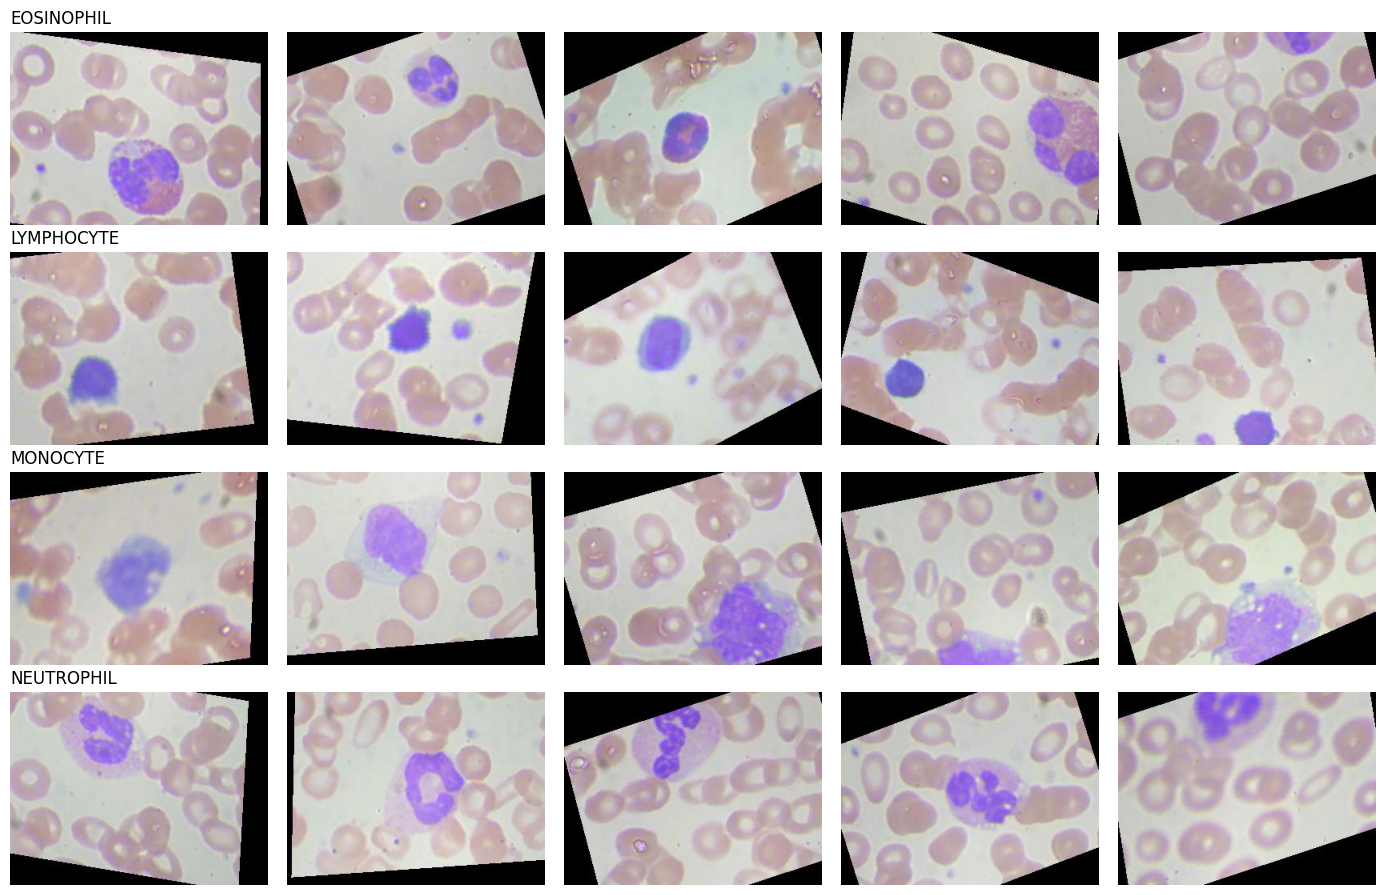

In [5]:
# cinco imagenes al azar de cada clase
fig, ejes = plt.subplots(len(clases), 5, figsize=(14, 9))
for i, clase in enumerate(clases):
    archivos = np.random.choice(os.listdir(ruta / "TRAIN" / clase), 5, replace=False)
    for j, archivo in enumerate(archivos):
        ejes[i, j].imshow(keras.utils.load_img(ruta / "TRAIN" / clase / archivo))
        ejes[i, j].axis("off")
    ejes[i, 0].set_title(clase, loc="left")
plt.tight_layout()
plt.show()

En cada imagen hay un globulo blanco, tenido de morado, rodeado de globulos rojos. Lo que cambia entre clases es sobre todo el nucleo: en el linfocito es redondo y ocupa casi toda la celula, en el monocito es grande y con forma de rinon, en el neutrofilo esta dividido en varios lobulos y en el eosinofilo suele tener dos lobulos. El eosinofilo y el neutrofilo son los mas parecidos entre si, asi que se espera que sean las clases que mas se confundan.

Tambien se observa que muchas imagenes estan rotadas o desplazadas y tienen esquinas negras. Esto indica que las imagenes ya pasaron por un proceso de aumento de datos.

Paso 5. Imagenes originales e imagenes aumentadas

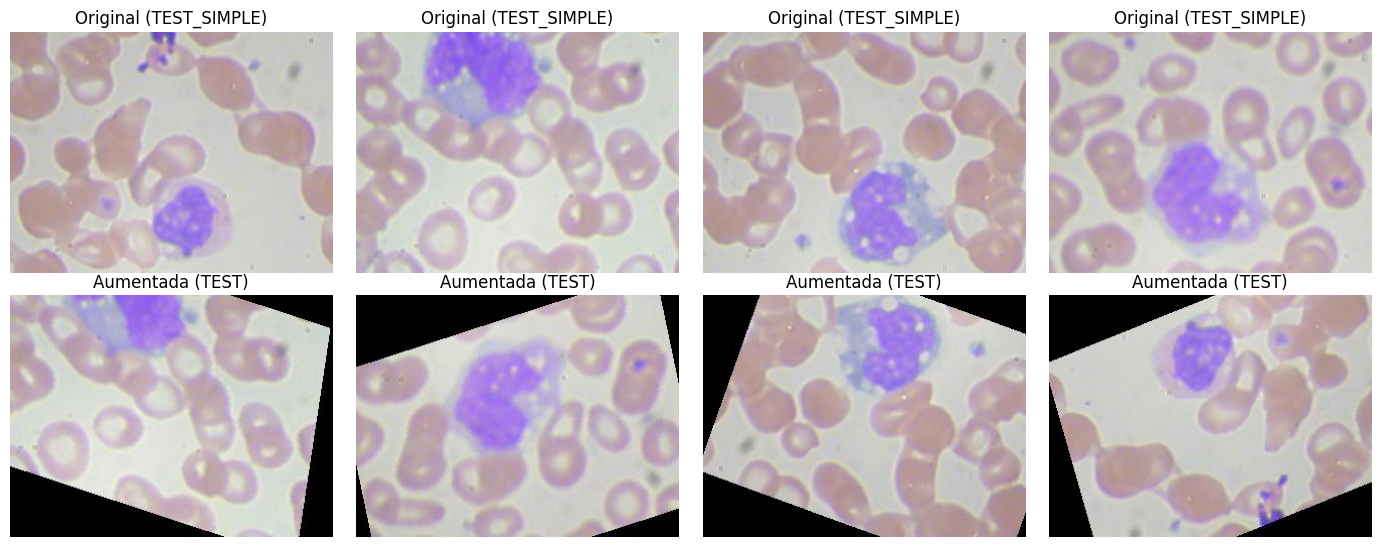

In [6]:
# los monocitos originales de TEST_SIMPLE y cuatro monocitos de TEST
originales = sorted(os.listdir(ruta / "TEST_SIMPLE" / "MONOCYTE"))
aumentadas = np.random.choice(os.listdir(ruta / "TEST" / "MONOCYTE"), 4, replace=False)
fig, ejes = plt.subplots(2, 4, figsize=(14, 5.5))
for j, archivo in enumerate(originales):
    ejes[0, j].imshow(keras.utils.load_img(ruta / "TEST_SIMPLE" / "MONOCYTE" / archivo))
    ejes[0, j].set_title("Original (TEST_SIMPLE)")
for j, archivo in enumerate(aumentadas):
    ejes[1, j].imshow(keras.utils.load_img(ruta / "TEST" / "MONOCYTE" / archivo))
    ejes[1, j].set_title("Aumentada (TEST)")
for eje in ejes.flat:
    eje.axis("off")
plt.tight_layout()
plt.show()

TEST_SIMPLE tiene 4 monocitos y TEST tiene 620. Al comparar las imagenes se observa que los monocitos de TEST son las mismas celulas de TEST_SIMPLE, pero rotadas, desplazadas o volteadas. Es decir, las imagenes de TEST no son fotos independientes, sino muchas versiones de pocas fotos originales. Lo mismo pasa en TRAIN.

Un detalle a senalar: esto afecta como se deben leer los resultados. El accuracy de prueba se calcula con pocas celulas distintas por clase, y en el caso de los monocitos con solo 4. Ademas, como las celulas de TEST son distintas a las de TRAIN, el conjunto de prueba mide que tan bien clasifica el modelo celulas que nunca vio, que es lo que interesa en la practica.

Paso 6. Separacion en entrenamiento, validacion y prueba

In [7]:
# tamano de entrada y tamano de lote
alto = 120
ancho = 160
lote = 32

# entrenamiento y validacion salen de TRAIN (80 y 20 por ciento)
datos_entrenamiento = keras.utils.image_dataset_from_directory(
    ruta / "TRAIN", validation_split=0.2, subset="training", seed=0,
    image_size=(alto, ancho), batch_size=lote)
datos_validacion = keras.utils.image_dataset_from_directory(
    ruta / "TRAIN", validation_split=0.2, subset="validation", seed=0,
    image_size=(alto, ancho), batch_size=lote)

# prueba: la carpeta TEST completa, sin revolver
datos_prueba = keras.utils.image_dataset_from_directory(
    ruta / "TEST", shuffle=False, image_size=(alto, ancho), batch_size=lote)

print("Clases:", datos_entrenamiento.class_names)

datos_entrenamiento = datos_entrenamiento.prefetch(tf.data.AUTOTUNE)
datos_validacion = datos_validacion.prefetch(tf.data.AUTOTUNE)
datos_prueba = datos_prueba.prefetch(tf.data.AUTOTUNE)

Found 9957 files belonging to 4 classes.


Using 7966 files for training.


Found 9957 files belonging to 4 classes.


Using 1991 files for validation.


Found 2487 files belonging to 4 classes.


Clases: ['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL']


Se respeta la separacion que trae el dataset: la carpeta TEST se usa completa como conjunto de prueba (2487 imagenes) y no se toca durante el entrenamiento. La carpeta TRAIN se divide en 80 por ciento para entrenamiento (7966 imagenes) y 20 por ciento para validacion (1991 imagenes). TEST_SIMPLE no se usa como conjunto de prueba porque sus celulas son las mismas de TEST.

Como preprocesamiento, las imagenes se reducen a la mitad, de 240x320 a 120x160, para que el entrenamiento sea mas rapido. Se conserva la proporcion original, asi que las celulas no se deforman. El paso de 0-255 a 0-1 se hace dentro del modelo con una capa Rescaling.

Un detalle a senalar: la validacion se saca al azar de TRAIN, y por lo visto en el Paso 5, TRAIN tiene varias versiones aumentadas de la misma celula. Entonces es muy probable que una celula tenga algunas versiones en entrenamiento y otras en validacion. Por eso el accuracy de validacion puede salir mas alto de lo que el modelo lograria con celulas nuevas, y el conjunto de prueba es la medida mas confiable de generalizacion.

Desarrollo del modelo

Paso 7. Arquitectura

Se construye una red convolucional sencilla como modelo base, sin tecnicas de regularizacion, para tener un punto de partida y poder medir despues el efecto de cada cambio. La red tiene cuatro bloques de convolucion con max pooling. Las capas convolucionales usan filtros de 3x3 con activacion relu, y el numero de filtros crece de 32 a 128 conforme la imagen se hace mas pequena: las primeras capas detectan bordes y colores, y las ultimas combinan esos patrones en formas mas complejas, como los lobulos del nucleo. Cada max pooling reduce el alto y el ancho a la mitad.

Al final, la capa Flatten convierte los mapas de caracteristicas en un vector, que pasa por una capa densa de 128 neuronas y por la capa de salida de 4 neuronas con activacion softmax, una por clase.

In [8]:
# modelo base: 4 bloques conv + pooling y un clasificador denso
modelo_base = keras.Sequential([
    keras.Input(shape=(alto, ancho, 3)),
    layers.Rescaling(1.0 / 255),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(4, activation="softmax"),
])
modelo_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 120, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 118, 158, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 59, 79, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 57, 77, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 28, 38, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 26, 36, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 13, 18, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 11, 16, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 5120)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         655,488 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 896,836 (3.42 MB)

 Trainable params: 896,836 (3.42 MB)

 Non-trainable params: 0 (0.00 B)

El modelo tiene 896,836 parametros entrenables. La imagen entra de 120x160 y, despues de los cuatro bloques, queda en mapas de 5x8 con 128 filtros, que al aplanarse dan un vector de 5120 valores. La mayor parte de los parametros esta en la primera capa densa, con 655,488, que es cerca del 73 por ciento del total. Las cuatro capas convolucionales juntas suman 240,832.

Paso 8. Entrenamiento

In [9]:
# compilacion y entrenamiento del modelo base
epocas = 20
modelo_base.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0001),
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])
historial_base = modelo_base.fit(datos_entrenamiento,
                                 validation_data=datos_validacion,
                                 epochs=epocas, verbose=2)

Epoch 1/20


249/249 - 37s - 150ms/step - accuracy: 0.2523 - loss: 1.3867 - val_accuracy: 0.2727 - val_loss: 1.3806


Epoch 2/20


249/249 - 31s - 127ms/step - accuracy: 0.3753 - loss: 1.2904 - val_accuracy: 0.5148 - val_loss: 1.1487


Epoch 3/20


249/249 - 33s - 131ms/step - accuracy: 0.5498 - loss: 1.0090 - val_accuracy: 0.6067 - val_loss: 0.8863


... (30 outputs left out)

Epoch 19/20


249/249 - 35s - 139ms/step - accuracy: 0.9436 - loss: 0.1521 - val_accuracy: 0.8980 - val_loss: 0.2355


Epoch 20/20


249/249 - 37s - 147ms/step - accuracy: 0.9573 - loss: 0.1332 - val_accuracy: 0.9016 - val_loss: 0.2251


Se usa el optimizador Adam con una tasa de aprendizaje de 0.0001. La funcion de perdida es sparse categorical crossentropy porque es un problema de varias clases y las etiquetas vienen como enteros de 0 a 3, no en one-hot. La metrica es accuracy, que es adecuada porque las clases estan balanceadas.

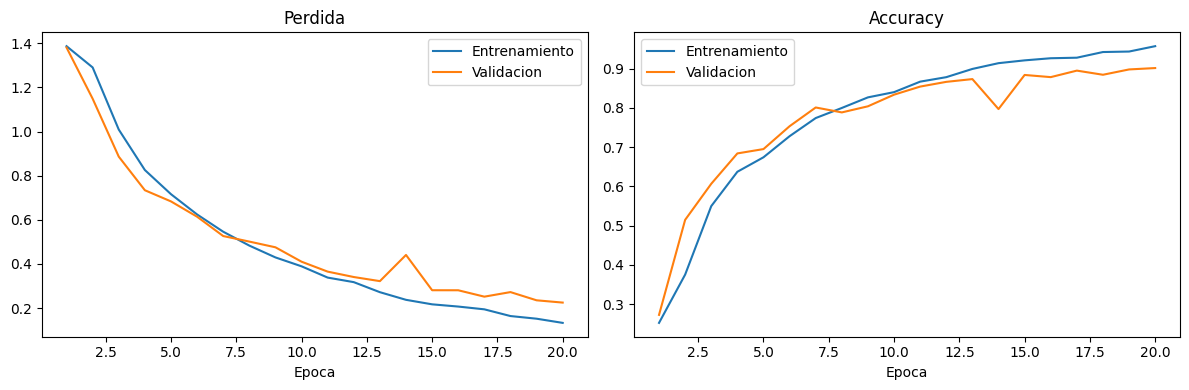

Ultima epoca: accuracy entrenamiento = 0.9573  accuracy validacion = 0.9016
Menor perdida de validacion en la epoca 20 : 0.2251


In [10]:
# curvas de perdida y accuracy
historia = historial_base.history
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(range(1, epocas + 1), historia["loss"], label="Entrenamiento")
ejes[0].plot(range(1, epocas + 1), historia["val_loss"], label="Validacion")
ejes[0].set_title("Perdida")
ejes[0].set_xlabel("Epoca")
ejes[0].legend()
ejes[1].plot(range(1, epocas + 1), historia["accuracy"], label="Entrenamiento")
ejes[1].plot(range(1, epocas + 1), historia["val_accuracy"], label="Validacion")
ejes[1].set_title("Accuracy")
ejes[1].set_xlabel("Epoca")
ejes[1].legend()
plt.tight_layout()
plt.show()

# resultados de la ultima epoca y mejor epoca en validacion
mejor = int(np.argmin(historia["val_loss"])) + 1
print("Ultima epoca: accuracy entrenamiento =", round(historia["accuracy"][-1], 4),
      " accuracy validacion =", round(historia["val_accuracy"][-1], 4))
print("Menor perdida de validacion en la epoca", mejor, ":", round(min(historia["val_loss"]), 4))

En la primera epoca el modelo practicamente no aprende: el accuracy es de 25.23 por ciento, igual que adivinar al azar entre 4 clases, y la perdida es de 1.3867. A partir de la segunda epoca la perdida empieza a bajar de forma constante.

Al final de las 20 epocas el accuracy de entrenamiento es de 95.73 por ciento y el de validacion de 90.16 por ciento. La menor perdida de validacion (0.2251) se da en la ultima epoca, lo que indica que el modelo todavia seguia mejorando cuando termino el entrenamiento y que 20 epocas no fueron suficientes para que convergiera.

Hasta la epoca 12 las dos curvas van practicamente juntas. Despues se empiezan a separar: el entrenamiento sigue subiendo mas rapido que la validacion y la diferencia final es de 5.6 puntos. Esto indica un inicio de sobreajuste, aunque todavia no es grave porque la perdida de validacion no ha empezado a subir. En la epoca 14 la validacion tiene una caida puntual (accuracy de 79.71 por ciento) y se recupera en la epoca siguiente.

Un detalle a senalar: por lo explicado en el Paso 6, el accuracy de validacion puede estar inflado porque comparte celulas con el entrenamiento. La evaluacion con el conjunto de prueba es la que dice que tanto generaliza el modelo.

In [11]:
# se guarda el modelo base (arquitectura y pesos)
os.makedirs(pathlib.Path("..") / "modelos", exist_ok=True)
modelo_base.save(pathlib.Path("..") / "modelos" / "modelo_base.keras")
print("Modelo guardado en modelos/modelo_base.keras")

Modelo guardado en modelos/modelo_base.keras


Paso 9. Evaluacion con entrenamiento, validacion y prueba

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# perdida y accuracy del modelo base en los tres conjuntos
evaluacion_base = pd.DataFrame(columns=["perdida", "accuracy"])
evaluacion_base.loc["entrenamiento"] = modelo_base.evaluate(datos_entrenamiento, verbose=0)
evaluacion_base.loc["validacion"] = modelo_base.evaluate(datos_validacion, verbose=0)
evaluacion_base.loc["prueba"] = modelo_base.evaluate(datos_prueba, verbose=0)
print(evaluacion_base.round(4))

               perdida  accuracy
entrenamiento   0.1057    0.9674
validacion      0.2251    0.9016
prueba          0.5607    0.7748


El accuracy es de 96.74 por ciento en entrenamiento, 90.16 por ciento en validacion y 77.48 por ciento en prueba. El de entrenamiento es un poco mayor al que se vio en la ultima epoca (95.73) porque aquel es el promedio de la epoca, mientras los pesos todavia estaban cambiando, y este se calcula con los pesos finales.

Los tres valores estan muy por encima del 25 por ciento que daria adivinar al azar, asi que el modelo si aprendio a distinguir las clases. Como el accuracy de entrenamiento es alto, el modelo no tiene un problema de sesgo: tiene capacidad suficiente para ajustarse a los datos.

El problema esta en la diferencia entre conjuntos. De entrenamiento a prueba se pierden 19.3 puntos de accuracy y la perdida pasa de 0.1057 a 0.5607. Esto indica sobreajuste (varianza alta): el modelo aprendio detalles de las imagenes de entrenamiento que no le sirven con imagenes nuevas.

Tambien se observa que la validacion queda 12.7 puntos arriba de la prueba. Como la validacion comparte celulas con el entrenamiento y la prueba no, este resultado confirma lo que se anticipo en el Paso 6: la validacion sobreestima el desempeno real, y el numero que se debe tomar como referencia es el de prueba.

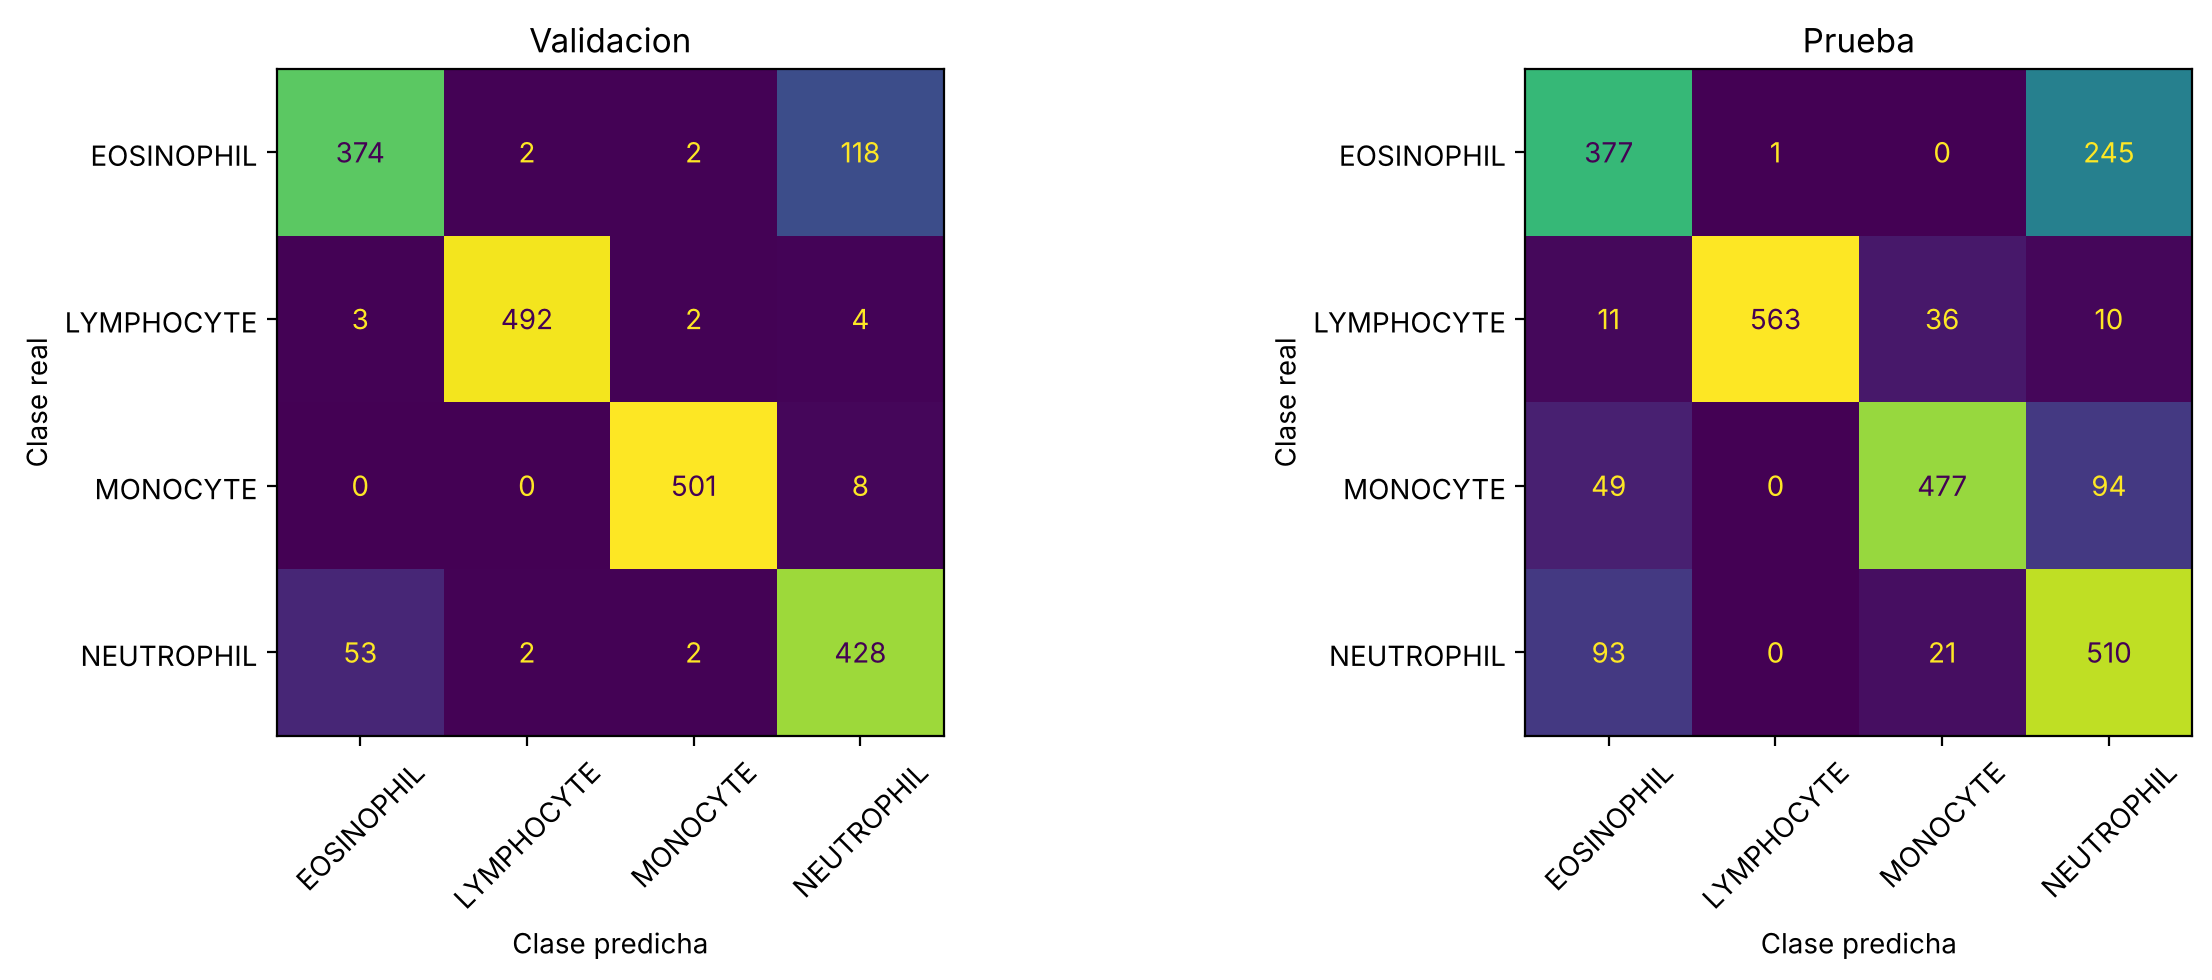

In [13]:
# etiquetas reales y predicciones de un conjunto, lote por lote
def predecir(modelo, datos):
    reales = []
    predichas = []
    for imagenes, etiquetas in datos:
        reales.append(etiquetas.numpy())
        predichas.append(np.argmax(modelo.predict_on_batch(imagenes), axis=1))
    return np.concatenate(reales), np.concatenate(predichas)

reales_val, pred_val = predecir(modelo_base, datos_validacion)
reales_prueba, pred_prueba = predecir(modelo_base, datos_prueba)

# matrices de confusion (filas: clase real, columnas: clase predicha)
matriz_val = confusion_matrix(reales_val, pred_val)
matriz_prueba = confusion_matrix(reales_prueba, pred_prueba)
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(matriz_val, display_labels=clases).plot(ax=ejes[0], colorbar=False, xticks_rotation=45)
ConfusionMatrixDisplay(matriz_prueba, display_labels=clases).plot(ax=ejes[1], colorbar=False, xticks_rotation=45)
ejes[0].set_title("Validacion")
ejes[1].set_title("Prueba")
for eje in ejes:
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

In [14]:
# accuracy por clase: aciertos de la diagonal entre el total de cada fila
por_clase = pd.DataFrame(index=clases)
por_clase["validacion"] = np.diag(matriz_val) / matriz_val.sum(axis=1)
por_clase["prueba"] = np.diag(matriz_prueba) / matriz_prueba.sum(axis=1)
por_clase["diferencia"] = por_clase["validacion"] - por_clase["prueba"]
print(por_clase.round(4))

# comprobacion a mano del accuracy de prueba
print("Accuracy de prueba a mano:", round(np.diag(matriz_prueba).sum() / matriz_prueba.sum(), 4))

            validacion  prueba  diferencia
EOSINOPHIL      0.7540  0.6051      0.1489
LYMPHOCYTE      0.9820  0.9081      0.0740
MONOCYTE        0.9843  0.7694      0.2149
NEUTROPHIL      0.8825  0.8173      0.0652
Accuracy de prueba a mano: 0.7748


En la prueba el modelo se equivoca en 560 de las 2487 imagenes. El error mas grande es entre eosinofilo y neutrofilo: 245 eosinofilos se clasifican como neutrofilo y 93 neutrofilos como eosinofilo. Juntas, estas dos confusiones suman 338 errores, que es el 60.4 por ciento de todos los errores. En validacion pasa lo mismo, con 118 y 53 casos. Esto coincide con lo que se vio en los ejemplos del Paso 4, donde estas dos clases eran las mas parecidas a simple vista. El eosinofilo es la clase con peor resultado: solo se reconoce el 60.51 por ciento en prueba.

El linfocito es la clase mas facil, con 90.81 por ciento en prueba. Su nucleo redondo que llena casi toda la celula lo distingue de las demas.

El monocito es la clase que mas cae entre conjuntos: pasa de 98.43 por ciento en validacion a 76.94 por ciento en prueba, una diferencia de 21.5 puntos. En validacion solo tiene 8 errores y en prueba tiene 143, la mayoria hacia neutrofilo (94). Un detalle a senalar: los 620 monocitos de prueba salen de solo 4 celulas originales, asi que cada celula aporta cerca de 155 imagenes. Si el modelo no reconoce bien una de esas celulas, falla en todas sus versiones a la vez, y eso es consistente con una caida de este tamano.

En resumen, el modelo base aprende pero sobreajusta, y sus errores se concentran en el par eosinofilo-neutrofilo. Estos dos puntos son los que se buscan mejorar en el ajuste del modelo.